In [1]:
import numpy as np
import matplotlib.pyplot as plt
import json
import h5py

In [2]:
## Global plot style

plt.rcParams.update({
    'axes.linewidth': 2.0,
    'axes.labelsize': 14,
    'axes.labelweight': 'normal',
    'xtick.major.width': 2.0,
    'ytick.major.width': 2.0,
    'xtick.minor.width': 1.5,
    'ytick.minor.width': 1.5,
    'xtick.major.size': 6,
    'ytick.major.size': 6,
    'xtick.minor.size': 4,
    'ytick.minor.size': 4,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12})

## Method to bold the tick labels

def bold_ticks(*axes):
    for ax in axes:
        labels = (ax.get_xticklabels() + ax.get_yticklabels()
            + ax.get_xticklabels(minor = True) + ax.get_yticklabels(minor = True))

        for label in labels:
            label.set_fontweight('bold')

In [3]:
# Planetesimal-radius bounds where power-law segments meet
_R_BREAK_POLLUTION = 2e5

_R_BREAK_FRAG_1 = 1e5
_R_BREAK_FRAG_2 = 8e6

def pollution_boundary(R_pltsml):
    """Envelope mass at which a planetesimal of radius R_pltsml is fully destroyed (destroyed fraction = 1)."""
    R_pltsml = np.asarray(R_pltsml, dtype = float)
    M_env = np.full_like(R_pltsml, np.nan)

    lower = R_pltsml <= _R_BREAK_POLLUTION
    M_env[lower] = (5.12e6 / R_pltsml[lower]) ** (1 / 4.679)

    upper = R_pltsml > _R_BREAK_POLLUTION
    M_env[upper] = (R_pltsml[upper] / 3.29e6) ** (1 / 0.888)

    return M_env

def fragmentation_boundary(R_pltsml):
    """Envelope mass below which a planetesimal of radius R_pltsml reaches the core (destroyed fraction = 0)."""
    R_pltsml = np.asarray(R_pltsml, dtype = float)
    M_env = np.full_like(R_pltsml, np.nan)

    lower = R_pltsml < _R_BREAK_FRAG_1
    M_env[lower] = (1.12e2 / R_pltsml[lower]) ** (1 / 1.737)

    middle = (R_pltsml >= _R_BREAK_FRAG_1) & (R_pltsml <= _R_BREAK_FRAG_2)
    M_env[middle] = 0.02

    upper = (R_pltsml > _R_BREAK_FRAG_2)
    M_env[upper] = (R_pltsml[upper] / 6.84e7) ** (1 / 0.548)

    return M_env

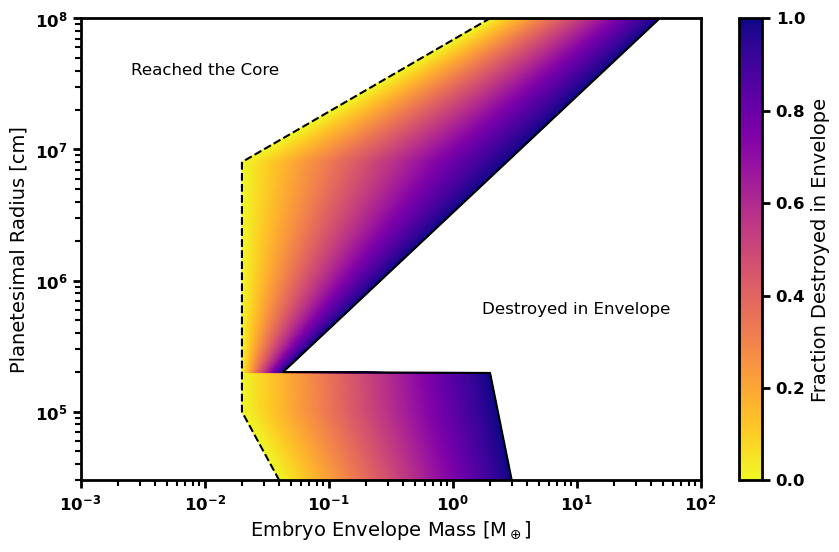

In [4]:
fig, ax = plt.subplots(figsize=(10, 6))

R_pltsml = np.logspace(np.log10(3e4), np.log10(1e8), 500)

M_pollution = pollution_boundary(R_pltsml)
M_fragmentation = fragmentation_boundary(R_pltsml)

u = np.linspace(0, 1, 100)
U = np.tile(u, (len(R_pltsml), 1))

LX = (1 - U) * np.log10(M_fragmentation)[:, None] + U * np.log10(M_pollution)[:, None]
LY = np.tile(np.log10(R_pltsml)[:, None], (1, len(u)))

pc = ax.pcolormesh(10 ** LX, 10 ** LY, U, shading = 'gouraud', cmap = 'plasma_r', zorder = 1)
cbar = fig.colorbar(pc, ax = ax, label = 'Fraction Destroyed in Envelope')

ax.plot(M_pollution, R_pltsml, color = 'black', linestyle = 'solid', zorder = 2)
ax.plot(M_fragmentation, R_pltsml, color = 'black', linestyle = 'dashed', zorder = 2)

ax.text(1e-2, 4e7, 'Reached the Core', fontsize = 12, color = 'black', rotation = 0, va = 'center', ha = 'center')
ax.text(1e1, 6e5, 'Destroyed in Envelope', fontsize = 12, color = 'black', rotation = 0, va = 'center', ha = 'center')

ax.set_xscale('log')
ax.set_yscale('log')

ax.set_ylim(3e4, 1e8)
ax.set_xlim(1e-3, 1e2)

ax.set_xlabel(r'Embryo Envelope Mass [M$_\oplus$]')
ax.set_ylabel(r'Planetesimal Radius [cm]')

bold_ticks(ax, cbar.ax)

plt.show()

In [5]:
def epsilon_poll(M_env, R_pltsml):
    """
    Fraction of a planetesimal of radius R_pltsml destroyed in an envelope of mass M_env.

    1 at/beyond the pollution boundary, 0 at/before the fragmentation boundary,
    linearly interpolated (in log envelope mass) in between.
    """
    M_env = np.asarray(M_env, dtype = float)
    R_pltsml = np.asarray(R_pltsml, dtype = float)

    M_frag = fragmentation_boundary(R_pltsml)
    M_poll = pollution_boundary(R_pltsml)

    eps = (np.log10(M_env) - np.log10(M_frag)) / (np.log10(M_poll) - np.log10(M_frag))
    return np.clip(eps, 0, 1)

In [6]:
## Method to read data from an HDF5 dataset or group

def read_hdf5_array(obj):
    """
    Read data from either an HDF5 dataset or an HDF5 group.
    """

    ## Normal case (the data are stored as one HDF5 dataset)
    if isinstance(obj, h5py.Dataset):
        return np.array(obj)

    ## Ragged case (the data are stored as a group)
    elif isinstance(obj, h5py.Group):
        values = []

        for key in sorted(obj.keys(), key = int):
            values.append(np.array(obj[key]))

        return values

    ## Raise an error if an unexpected HDF5 object is encountered
    else:
        raise TypeError(f"Unexpected HDF5 object type: {type(obj)}")

## Method to load data from an HDF5 file

def load_data(data_dir, config_dir):
    """
    Load a disc evolution output file (HDF5 only).

    Parameters:
        data_dir: Path to the HDF5 output file.
        config_dir: Path to the JSON config file used for the run.

    Returns:
        data: Dictionary containing the simulation output.
        config: Dictionary containing the simulation config file.
    """

    data = {}

    ## Load the configuration file
    with open(config_dir, "r") as f:
        config = json.load(f)

    ## Open the HDF5 file in read-only mode
    with h5py.File(data_dir, "r") as f:

        ## -----------------------
        ## General simulation data
        ## -----------------------

        general_keys = [
            "R",
            "t",
            "disk_Mdot_star",
            "disk_Mass",
            "Tc",
            "Sigc"]

        for key in general_keys:
            ## Only load the quantity if it exists in the file
            if key in f:
                data[key] = np.array(f[key])

        ## -----------------
        ## Scalar attributes
        ## -----------------

        scalar_attributes = [
            "alpha_SS",
            "psi_DW",
            "Mdot",
            "Mdisk",
            "Rd",
            "pla_eff",
            "f_plt",
            "complete",
            "aborted"]

        for key in scalar_attributes:
            ## Only load the attribute if it exists in the file
            if key in f.attrs:
                data[key] = f.attrs[key].item()

        ## Names of the chemical species (only written when chemistry is on)
        if "chem_species" in f.attrs:
            data["chem_species"] = [s.decode() if isinstance(s, bytes) else str(s) for s in f.attrs["chem_species"]]

        ## -------------
        ## Disk profiles
        ## -------------

        disk_keys = [
            "T",
            "time_snap",
            "Sigma_G",
            "Sigma_dust",
            "Sigma_pebbles",
            "Sigma_planetesimals",
            "Vdrift_grains",
            "Vdrift_pebbles",
            "St_grains",
            "St_pebbles",
            "St_planetesimals",
            "e_planetesimals",
            "i_planetesimals",
            "de2_dt",
            "di2_dt",
            "de2_dt_drag",
            "di2_dt_drag",
            "de2_dt_VS_embryo",
            "di2_dt_VS_embryo",
            "de2_dt_VS_pltsml",
            "di2_dt_VS_pltsml",
            "de2_dt_DF",
            "di2_dt_DF",
            "gas_chem",
            "ice_chem",
            "planetesimal_ice_chem"]

        for key in disk_keys:
            ## Only load the quantity if it exists in the file
            if key in f:
                data[key] = read_hdf5_array(f[key])

        ## -----------
        ## Planet data
        ## -----------

        if config["planets"]["include_planets"]:
            planet_keys = [
                "Mcs",
                "Mes",
                "Rp",
                "disk_Mdot_p",
                "Mdot_planetesimal",
                "Mdot_pebble_core",
                "Mdot_pebble_env",
                "Mdot_migration",
                "Mdot_gas",
                "M_iso_planetesimal",
                "M_iso_pebble",
                "X_cores",
                "X_envs",
                "f_env",
                "t_form"]

            for key in planet_keys:
                ## Only load the quantity if it exists in the file
                if key in f:
                    data[key] = read_hdf5_array(f[key])

    return data, config

In [7]:
## Load data and config file

data_dir = "/Users/ben/Downloads/Planet Formation/DiscEvolution Simulations/Output/popsynth_default_model.h5"
config_dir = "/Users/ben/Downloads/Planet Formation/DiscEvolution Simulations/Config/popsynth_default_config.json"

data, config = load_data(data_dir, config_dir)

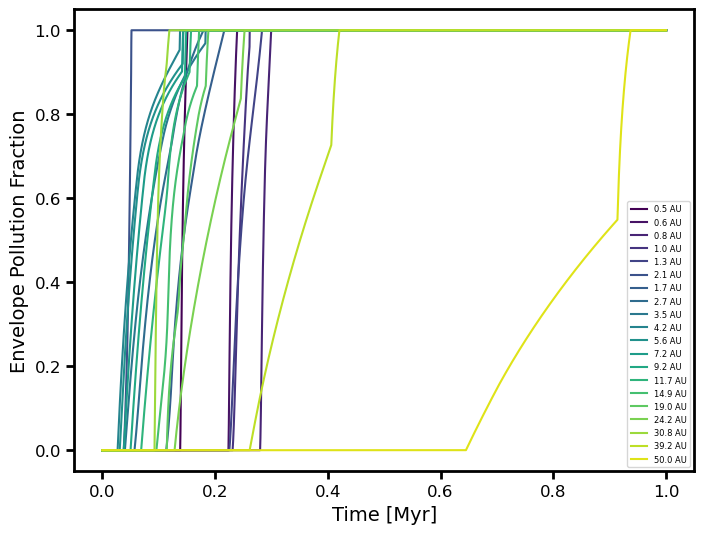

In [8]:
f_envs = np.nan_to_num(data["f_env"])
Rp = data["Rp"]
t = data["t"]

n_planets = len(Rp)
colors = [plt.cm.viridis(i / n_planets) for i in range(n_planets)]

fig, ax = plt.subplots(figsize=(8, 6))

for i in range(len(f_envs)):
    ax.plot(t / 3e6, f_envs[i], color = colors[i], label = f'{Rp[i][~np.isnan(Rp[i])][0]:.1f} AU')

ax.set_xlabel('Time [Myr]')
ax.set_ylabel('Envelope Pollution Fraction')
ax.legend(fontsize = 6, loc = 'lower right')

plt.show()

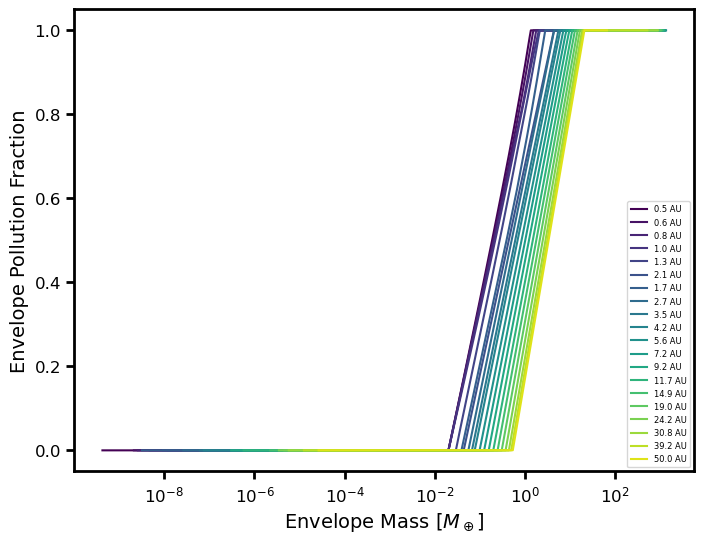

In [9]:
f_envs = np.nan_to_num(data["f_env"])
Rp = data["Rp"]
Mes = data["Mes"]

n_planets = len(Rp)
colors = [plt.cm.viridis(i / n_planets) for i in range(n_planets)]

fig, ax = plt.subplots(figsize=(8, 6))

for i in range(len(f_envs)):
    ax.plot(Mes[i], f_envs[i], color = colors[i], label = f'{Rp[i][~np.isnan(Rp[i])][0]:.1f} AU')

ax.set_xscale('log')
ax.set_xlabel(r'Envelope Mass [$M_\oplus$]')
ax.set_ylabel('Envelope Pollution Fraction')
ax.legend(fontsize = 6, loc = 'lower right')

plt.show()